<div dir="rtl">

### مراحل :
1. **بررسی یک متن خام یکپارچه و شلوغ** (شامل تگ‌های HTML، لینک، ایمیل، هشتگ، منشن، حروف و اعداد عربی، اعراب، کشیده، ایموجی، کاراکترهای نامرئی یونیکد و غلط‌های نیم‌فاصله)
2. **پاک‌سازی متن (Text Cleaning)** (حذف نویزها و کاراکترهای نامرئی + ثبت آمار طول و بایت‌ها)
3. **نرمال‌سازی (Normalization)** (نرمال‌ساز دستی با Unicode و Regex + تست Idempotency + مقایسه با `Hazm`)
4. **توکنایزیشن (Tokenization)** (جمله‌بندی و واژه‌بندی دستی با حفظ نیم‌فاصله و نشانه‌ها + مقایسه با `Hazm`)
5. **مدیریت ایست‌واژه‌ها (Stopwords)** (روش لیستی با `Hazm` + روش آماری `IDF = ln(N/df)` روی جملات متن + حفظ افعال نفی)
6. **ریشه‌یابی (Stemming & Lemmatization)** (ساخت ریشه‌یاب دستی + مقایسه با `Stemmer` و `Lemmatizer` کتابخانه `Hazm`)
7. **نمایش متن و مدل‌سازی (BoW, N-gram, TF-IDF, Cosine Similarity)** (محاسبه دستی فرمول‌ها روی جملات متن و مقایسه با `Scikit-Learn`)

</div>

In [1]:
import re
import math
import html
import unicodedata
from collections import Counter
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd

# Talash baraye import kardan e Hazm (agar nasb nabashad ham bakhsh haye dasti ejra mishavand)
try:
    from hazm import Normalizer, sent_tokenize, word_tokenize, Stemmer, Lemmatizer, stopwords_list
    HAZM_AVAILABLE = True
    print("[OK] Ketabkhane Hazm ba movafaghiat load shod.")
except ImportError:
    HAZM_AVAILABLE = False
    print("[WARN] Hazm nasb nist; bakhsh haye dasti bedoone moshkel ejra mishavand.")

[OK] Ketabkhane Hazm ba movafaghiat load shod.




<div dir="rtl">

## ۱. متن خام یکپارچه، طولانی و پرنویز (Raw Text)
به جای چند سند پراکنده، یک **متن خام واحد و سنگین** داریم (مثلاً یک نقد و بررسی طولانی از یک دوره آموزشی در شبکه‌های اجتماعی و وب) که **همه‌ی چالش‌های مطرح شده در کلاس** را یکجا درون خودش دارد:
* تگ‌های HTML و موجودیت‌های وب (`<div>`, `<p>`, `&nbsp;`, `&amp;`)
* لینک (`URL`)، ایمیل، منشن (`@user`) و هشتگ (`#هوش_مصنوعی`)
* حروف عربی به جای فارسی (`ي`، `ك`، `ة`، `أ`) و سه مدل رقم مختلف (`١٢٠` عربی، `120000` انگلیسی، `۲۵۰۰` فارسی)
* کشیده (`ـــــ`)، اعراب (`فَتحه، کَسره، ضَمه`) و تکرار حروف برای هیجان (`سلاااااام`، `عااااالیییی`)
* کاراکترهای نامرئی یونیکد (`\u200b` فضای صفر عرض، `\ufeff` کاراکتر BOM، `\u200e` کاراکتر جهت‌دهی)
* مشکلات فاصله و نیم‌فاصله (`کتاب ها`، `میروم`، `بزرگ تر`، `می خوام`) و جملات مثبت و منفی کنار هم.

</div>

In [2]:
# Tarif e yek matn e kham e yekparche, sholoogh va por az noise baraye anjam e tamame marahel
raw_text = """<div class="review-box">
سلاااااام به همگی!! 😍🔥 این دوره ی #هوش_مصنوعی و #پردازش_زبان_طبیعی واقعا عااااالیییی و بی‌نظیر بود؛ من قبلا هیچی از برنامه‌نویسی نمیدونستم ولی الان هر روز میروم و کتاب ها و مقاله های انگلیسی رو میخونم!!
لینک جزوه جلسه دوم: https://nlp-course.ir/notes/session2?id=123&lang=fa و ایمیل استاد: ostad.nlp@university.ac.ir است.
قیمت كتاب هم ١٢٠ هزار تومان (120000 تومان و ۱۲۰,۰۰۰ ریال) بود كه خيلي مناسبه! &nbsp; @ali_rezaei_99
<p>متأسفانه کیفیت صدا در جلسه ی اول اصلا خوب نبود... 😡💔 تازه فایل PDF هم حروفش به هم ریخته بود و کلماتش کشــــــیده و با اعرابِ عجیب (مَثَلاً كِتابِ خُوب) نوشته شده بود!!</p>
در کلاس پردازش زبان طبیعی یاد گرفتیم که اگر متن خام و کثیف باشد، خروجی مدل هم خراب میشود (Garbage In, Garbage Out).
حتما کتاب های مرجع مثل کتاب جرافسکی (Jurafsky) را مطالعه کنید! 📚💡 این کتاب‌ها بزرگ ترین منبع یادگیری هستند و تعداد بازدیدهای این فیلم آموزشی در کمتر از ۲۴ ساعت به ۲۵۰۰ نفر رسید. #یادگیری_ماشین #فیلم_آموزشی
​‎﻿
</div>"""

In [3]:
# Barresi e matn e kham az nazar e tedad character (Code Points) va hajm e byte dar UTF-8
print("=== Namayesh e Matn e Kham (Raw Text) ===")
print(raw_text)
print("-" * 70)
print(f"Tedad character ha (Code Points): {len(raw_text)}")
print(f"Hajm dar hafeze ba UTF-8 (Bytes): {len(raw_text.encode('utf-8'))} bytes")
print(f"Test e nokte kelasi -> Tool e nim-fasele(ZWNJ): {len('\u200c')} | Byte nim-fasele (ZWNJ) dar UTF-8: {len('\u200c'.encode('utf-8'))} bytes")

=== Namayesh e Matn e Kham (Raw Text) ===
<div class="review-box">
سلاااااام به همگی!! 😍🔥 این دوره ی #هوش_مصنوعی و #پردازش_زبان_طبیعی واقعا عااااالیییی و بی‌نظیر بود؛ من قبلا هیچی از برنامه‌نویسی نمیدونستم ولی الان هر روز میروم و کتاب ها و مقاله های انگلیسی رو میخونم!!
لینک جزوه جلسه دوم: https://nlp-course.ir/notes/session2?id=123&lang=fa و ایمیل استاد: ostad.nlp@university.ac.ir است.
قیمت كتاب هم ١٢٠ هزار تومان (120000 تومان و ۱۲۰,۰۰۰ ریال) بود كه خيلي مناسبه! &nbsp; @ali_rezaei_99
<p>متأسفانه کیفیت صدا در جلسه ی اول اصلا خوب نبود... 😡💔 تازه فایل PDF هم حروفش به هم ریخته بود و کلماتش کشــــــیده و با اعرابِ عجیب (مَثَلاً كِتابِ خُوب) نوشته شده بود!!</p>
در کلاس پردازش زبان طبیعی یاد گرفتیم که اگر متن خام و کثیف باشد، خروجی مدل هم خراب میشود (Garbage In, Garbage Out).
حتما کتاب های مرجع مثل کتاب جرافسکی (Jurafsky) را مطالعه کنید! 📚💡 این کتاب‌ها بزرگ ترین منبع یادگیری هستند و تعداد بازدیدهای این فیلم آموزشی در کمتر از ۲۴ ساعت به ۲۵۰۰ نفر رسید. #یادگیری_ماشین #فیلم_آموزشی
​‎﻿
</div>
---



<div dir="rtl">

## ۲. پاک‌سازی متن (Text Cleaning)
در این مرحله نویزهایی که اطلاعات مفیدی به مدل نمی‌دهند را پاک می‌کنیم یا با نشانه ثابت (`<URL>`, `<EMAIL>`) جایگزین می‌کنیم.
* **نکته مهم کلاسی (ترتیب اجرا):** جایگزینی لینک (`URL`) و ایمیل باید **قبل از** دستکاری اعداد انجام شود؛ چون داخل لینک‌ها عدد وجود دارد (مثل `session2?id=123`) و اگر اول اعداد را تغییر دهیم، ساختار لینک خراب می‌شود.
* **حذف کاراکترهای نامرئی:** کاراکترهای مزاحم مثل `ZWSP (\u200b)` و `BOM (\ufeff)` را حذف می‌کنیم، اما **مراقبیم نیم‌فاصله (`\u200c`) حذف نشود** تا کلمات مرکب از هم نپاشند.

* **فضای صفر عرض (`ZWSP` - `\u200b`):** کاراکتری نامرئی است که دیده نمی‌شود ولی بین حروف قرار می‌گیرد و باعث می‌شود یک کلمه واحد برای کامپیوتر متفاوت شناخته شود (برخلاف نیم‌فاصله `\u200c` که در فارسی ضروری است).
* **نشانگر ترتیب بایت (`BOM` - `\ufeff`):** کاراکتر نامرئی ابتدای فایل‌های متنی (به‌خصوص در ویندوز) که به اولین کلمه متن می‌چسبد و شناسایی آن را مختل می‌کند.


* **چرا نیم‌فاصله (`\u200c` یا ZWNJ) را حذف نمی‌کنیم؟** نیم‌فاصله برخلاف `ZWSP` نویز نیست؛ بلکه یک جداکننده ضروری در زبان فارسی است که اجزای کلمات مرکب (مثل *می‌روم* یا *کتاب‌ها*) را از هم جدا نگه می‌دارد تا به هم نچسبند و ابزارهای بعدی (مثل توکنایزر و ریشه‌یاب `Hazm`) بتوانند مرز کلمات را درست تشخیص دهند.
</div>


In [4]:
def clean_text_manual(text, keep_emoji=False):
    # 1. Tabdil e HTML entities mesle &nbsp; va &amp; be character e standard
    text = html.unescape(text)
    
    # 2. Hazf e tag haye HTML mesle <div> va <p>
    text = re.sub(r"<[^>]+>", " ", text)
    
    # 3. Jaygozini e link ha ba neshane <URL> (hatman ghabl az jaygozini e adad!)
    text = re.sub(r"https?://\S+", " <URL> ", text)
    
    # 4. Jaygozini e email ha ba neshane <EMAIL>
    text = re.sub(r"[\w.+-]+@[\w-]+\.[\w.-]+", " <EMAIL> ", text)
    
    # 5. Hazf e mention ha (@username) va tabdil e hashtag (#hoosh_masnooei) be kalamat e mamooli
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", lambda m: " " + m.group(1).replace("_", " ") + " ", text)
    
    # 6. Hazf e character haye namarei mozahem (ZWSP, LRM, RLM, BOM) be joz (((((((((((((((((nim-fasele (‌))))))))))))))))
    text = re.sub(r"[\u200b\u200e\u200f\u202a-\u202e\u2060\u00ad\ufeff]", "", text)
    
    # 7. Modiriat e emoji ha (vabaste be masale: dar sentiment negah midarim, dar topic hazf mikonim)
    if not keep_emoji:
        emoji_pattern = re.compile(
            "["
            "\U0001F600-\U0001F64F"  # Emoji haye soorat
            "\U0001F300-\U0001F5FF"  # Namad ha va ashkal
            "\U0001F680-\U0001F6FF"  # Haml o naghl
            "\U0001F1E0-\U0001F1FF"  # Parcham ha
            "\U00002702-\U000027B0"
            "\U0001F900-\U0001F9FF"
            "]+", flags=re.UNICODE
        )
        text = emoji_pattern.sub(" ", text)
        
    # 8. Hazfe fasele haye ezafe va khat haye jadid e tekrari
    text = re.sub(r"\s+", " ", text).strip()
    return text

cleaned_text = clean_text_manual(raw_text, keep_emoji=False)

print("=== Moghayese Ghabl va Bad az Pak-sazi (Cleaning) ===")
print(f"Tool e matn ghabl: {len(raw_text)} chars | Tool e matn bad: {len(cleaned_text)} chars")
print("-" * 70)
print(cleaned_text)

# faqat baraye namayesh e khorooji e BeautifulSoup va tabe dasti ma (clean_text_manual)
try:
   
    # Pak-sazi faghat ba ketabkhane BeautifulSoup
    soup_clean = BeautifulSoup(raw_text, "html.parser").get_text(separator=" ")
    soup_clean = re.sub(r"\s+", " ", soup_clean).strip()
    
    print("=== 1. Khorooji BeautifulSoup (Faghat HTML ha pak shodand) ===")
    print(soup_clean[:250] + "...")
    
    print("\n=== 2. Khorooji Tabe Dasti Ma (HTML + Link + Email + Emoji + Namarei ha) ===")
    print(cleaned_text[:250] + "...")
except ImportError:
    print("[INFO] Ketabkhane bs4 nasb nist (!pip install beautifulsoup4).")

=== Moghayese Ghabl va Bad az Pak-sazi (Cleaning) ===
Tool e matn ghabl: 954 chars | Tool e matn bad: 811 chars
----------------------------------------------------------------------
سلاااااام به همگی!! این دوره ی هوش مصنوعی و پردازش زبان طبیعی واقعا عااااالیییی و بی‌نظیر بود؛ من قبلا هیچی از برنامه‌نویسی نمیدونستم ولی الان هر روز میروم و کتاب ها و مقاله های انگلیسی رو میخونم!! لینک جزوه جلسه دوم: <URL> و ایمیل استاد: <EMAIL> است. قیمت كتاب هم ١٢٠ هزار تومان (120000 تومان و ۱۲۰,۰۰۰ ریال) بود كه خيلي مناسبه! متأسفانه کیفیت صدا در جلسه ی اول اصلا خوب نبود... تازه فایل PDF هم حروفش به هم ریخته بود و کلماتش کشــــــیده و با اعرابِ عجیب (مَثَلاً كِتابِ خُوب) نوشته شده بود!! در کلاس پردازش زبان طبیعی یاد گرفتیم که اگر متن خام و کثیف باشد، خروجی مدل هم خراب میشود (Garbage In, Garbage Out). حتما کتاب های مرجع مثل کتاب جرافسکی (Jurafsky) را مطالعه کنید! این کتاب‌ها بزرگ ترین منبع یادگیری هستند و تعداد بازدیدهای این فیلم آموزشی در کمتر از ۲۴ ساعت به ۲۵۰۰ نفر رسید. یادگیری ماشین فیلم آموزشی
=== 1

<div dir="rtl">

## ۳. نرمال‌سازی (Normalization)
هدف نرمال‌سازی این است که شکل‌های مختلف یک حرف یا واژه را به **یک شکل واحد و استاندارد** تبدیل کنیم:
1. **نرمال‌سازی یونیکد (`NFKC`):** یکسان‌سازی کاراکترهای سازگار. *(نکته: NFKC حروف `ي` و `ك` عربی را تبدیل نمی‌کند و باید خودمان جدول نگاشت بنویسیم).*
2. **نگاشت نویسه‌های فارسی:** تبدیل `ي` و `ى` به `ی`، تبدیل `ك` به `ک`، تبدیل `ة` به `ه`، و یکسان‌سازی تمام ارقام (عربی/فارسی/انگلیسی).
3. **حذف کشیده و اعراب + کاهش حروف تکراری:** تبدیل `عااااالیییی` به `عالی` و حذف فتحه/کسره/ضمه.
4. **اصلاح نیم‌فاصله (`ZWNJ`):** چسباندن صحیح پسوندها (`ها`، `تر`، `ترین`) و پیشوندها (`می`، `نمی`) با نیم‌فاصله.

در انتها نیز **تست Idempotency** می‌گیریم (اجرای مجدد تابع روی خروجی نباید متن را تغییر دهد) و خروجی را با `Normalizer` کتابخانه `Hazm` مقایسه می‌کنیم.
</div>


In [5]:
ZWNJ = "\u200c"  # Nim-fasele standard

def normalize_persian_manual(text, replace_numbers=True):
    # Gam 1: Normal-sazi e standard e Unicode (NFKC) va Case Folding (horoof e koochak englisi)
    text = unicodedata.normalize("NFKC", text).lower()
    
    # (Ekhtiari) Agar mikhahid kolle kalamat e englisi hazf shavand, khat e zir ra az comment kharej konid:
    # text = re.sub(r"[a-z]+", " ", text)
    
    # Gam 2: Jadval e negaasht e horoof e arabi be standard e farsi
    char_map = {
        "\u064A": "\u06CC",  # ي arabi -> ی farsi
        "\u0649": "\u06CC",  # ى alef maghsoore -> ی farsi
        "\u0643": "\u06A9",  # ك arabi -> ک فارسی
        "\u0629": "\u0647",  # ة -> ه
        "\u0623": "\u0627",  # أ -> ا
        "\u0625": "\u0627",  # إ -> ا
    }
    for i in range(10):
        char_map[chr(0x0660 + i)] = str(i)  # Argham e arabi
        char_map[chr(0x06F0 + i)] = str(i)  # Argham e farsi
        
    text = text.translate(str.maketrans(char_map))
    
    # Gam 3: Hazf e keshide (\u0640) va e'rab (\u064B ta \u065F)
    text = re.sub(r"[\u0640\u064B-\u065F]", "", text)
    
    # Gam 4: Kahesh e horoof e tekrari (3 bar ya bishtar -> 1 harf)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    
    # Gam 5: Eslah e nim-fasele haye rayej (ba shart e naboodan e nim-fasele ghabl az kalame baraye Idempotency)
    text = re.sub(rf"(?<!{ZWNJ})\b(ن?می)\s+([\u0600-\u06FF]+)", rf"\1{ZWNJ}\2", text)
    text = re.sub(r"([\u0600-\u06FF]+)\s+(های|ها|تر|ترین|ام|ات|اش)\b", rf"\1{ZWNJ}\2", text)
    text = re.sub(rf"(?<!{ZWNJ})\b(ن?می)(روم|خونم|شود|کند|کنم|تواند|دونستم)\b", rf"\1{ZWNJ}\2", text)
    
    # Gam 6: Tabdil e adad be <num>
    if replace_numbers:
        text = re.sub(r"\b\d+(?:[.,،]\d+)*\b", "<num>", text)
        
    # Gam 7: Yekdast-sazi e alaem e negareshi tekrari va hazf e nim-fasele tekrari
    text = re.sub(r"!+", "!", text)
    text = re.sub(r"؟+", "؟", text)
    text = re.sub(r"\.{2,}", ".", text)
    text = re.sub(rf"{ZWNJ}{{2,}}", ZWNJ, text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

normalized_text = normalize_persian_manual(cleaned_text)

print("=== Khorooji e Normalizer Dasti ===")
print(normalized_text)

# Moghayese ba Normalizer ketabkhane Hazm
# serfan baraye namayesh e khorooji e Normalizer Hazm 
try:
    hazm_norm = Normalizer()
    print("\n=== Khorooji e Normalizer Ketabkhane Hazm roye matn kham ===")
    print(hazm_norm.normalize(raw_text))
    print("\n=== Khorooji e Normalizer Ketabkhane Hazm roye matn clean ===")
    print(hazm_norm.normalize(cleaned_text))
except ImportError:
    print("\n[INFO] Hazm nasb nist; khorooji dasti kamelan amade ast.")

=== Khorooji e Normalizer Dasti ===
سلام به همگی! این دوره ی هوش مصنوعی و پردازش زبان طبیعی واقعا عالی و بی‌نظیر بود؛ من قبلا هیچی از برنامه‌نویسی نمی‌دونستم ولی الان هر روز می‌روم و کتاب‌ها و مقاله‌های انگلیسی رو می‌خونم! لینک جزوه جلسه دوم: <url> و ایمیل استاد: <email> است. قیمت کتاب هم <num> هزار تومان (<num> تومان و <num> ریال) بود که خیلی مناسبه! متاسفانه کیفیت صدا در جلسه ی اول اصلا خوب نبود. تازه فایل pdf هم حروفش به هم ریخته بود و کلماتش کشیده و با اعراب عجیب (مثلا کتاب خوب) نوشته شده بود! در کلاس پردازش زبان طبیعی یاد گرفتیم که اگر متن خام و کثیف باشد، خروجی مدل هم خراب می‌شود (garbage in, garbage out). حتما کتاب‌های مرجع مثل کتاب جرافسکی (jurafsky) را مطالعه کنید! این کتاب‌ها بزرگ‌ترین منبع یادگیری هستند و تعداد بازدیدهای این فیلم آموزشی در کمتر از <num> ساعت به <num> نفر رسید. یادگیری ماشین فیلم آموزشی

=== Khorooji e Normalizer Ketabkhane Hazm roye matn kham ===
<div class= «review-box» >
سلام به همگی!! 😍🔥 این دوره‌ی #هوش_مصنوعی و #پردازش_زبان_طبیعی واقعا عالی و بی‌نظیر بود

<div dir="rtl">

## ۴. توکنایزیشن (Tokenization)
شکستن متن به واحدهای کوچکتر (**جمله** و **کلمه/توکن**).
* **چرا `split()` ساده کافی نیست؟** اول اینکه علائم نگارشی به کلمات می‌چسبند (مثلاً `"خوب بود!"` یک توکن می‌شود). دوم اینکه در زبان فارسی، الگوی استاندارد انگلیسی (`\w+`) نیم‌فاصله (`\u200c`) را جداکننده می‌بیند و کلمه‌ای مثل `"کتاب‌ها"` را به دو تکه `"کتاب"` و `"ها"` می‌شکند!
* در اینجا متن یکپارچه خودمان را هم به **جملات مجزا** می‌شکنیم (که در مراحل بعدی از همین جملات برای محاسبه `IDF` و `TF-IDF` استفاده می‌کنیم) و هم به **توکن‌های واژگانی** تقسیم می‌کنیم.
</div>


In [6]:
def sentence_tokenize_manual(text):
    # Shekastan e matn be jomalat bar asas e alaem e payan e jomle (. ! ؟ ؛)
    sentences = re.split(r"(?<=[.!؟؛])\s+", text)
    return [s.strip() for s in sentences if s.strip()]

def word_tokenize_manual(text):
    # Olgooye hooshmand:
    # 1. Neshane haye khas mesle <URL>, <EMAIL>, <NUM> ra yekja negah midarad
    # 2. Kalamat e farsi ke vasateshan nim-fasele (‌) darand ra yek token e vahed migirad
    # 3. Kalamat e englisi va alaem e negareshi ra joda mikonad
    pattern = r"<[A-Z]+>|[\u0600-\u06FF]+(?:\u200c[\u0600-\u06FF]+)*|[a-zA-Z0-9_-]+|[.!؟،؛:]"
    return re.findall(pattern, text)

print("=== 1. Moghayese split() sade ba Tokenizer Dasti ===")
print("split() sade (ghalat - chasbidan e alaem):", normalized_text.split()[:12])
print("Tokenizer dasti (dorost):", word_tokenize_manual(normalized_text)[:15])

print("=== 2. Jomle-bandi Dasti (Sentence Tokenization) ===")
sentences = sentence_tokenize_manual(normalized_text)
for idx, s in enumerate(sentences, 1):
    print(f"Jomle {idx}: {s}")

if HAZM_AVAILABLE:
    print("=== 3. Moghayese ba Tokenizer Ketabkhane Hazm ===")
    print("Token haye Hazm:", word_tokenize(normalized_text)[:15])

=== 1. Moghayese split() sade ba Tokenizer Dasti ===
split() sade (ghalat - chasbidan e alaem): ['سلام', 'به', 'همگی!', 'این', 'دوره', 'ی', 'هوش', 'مصنوعی', 'و', 'پردازش', 'زبان', 'طبیعی']
Tokenizer dasti (dorost): ['سلام', 'به', 'همگی', '!', 'این', 'دوره', 'ی', 'هوش', 'مصنوعی', 'و', 'پردازش', 'زبان', 'طبیعی', 'واقعا', 'عالی']
=== 2. Jomle-bandi Dasti (Sentence Tokenization) ===
Jomle 1: سلام به همگی!
Jomle 2: این دوره ی هوش مصنوعی و پردازش زبان طبیعی واقعا عالی و بی‌نظیر بود؛
Jomle 3: من قبلا هیچی از برنامه‌نویسی نمی‌دونستم ولی الان هر روز می‌روم و کتاب‌ها و مقاله‌های انگلیسی رو می‌خونم!
Jomle 4: لینک جزوه جلسه دوم: <url> و ایمیل استاد: <email> است.
Jomle 5: قیمت کتاب هم <num> هزار تومان (<num> تومان و <num> ریال) بود که خیلی مناسبه!
Jomle 6: متاسفانه کیفیت صدا در جلسه ی اول اصلا خوب نبود.
Jomle 7: تازه فایل pdf هم حروفش به هم ریخته بود و کلماتش کشیده و با اعراب عجیب (مثلا کتاب خوب) نوشته شده بود!
Jomle 8: در کلاس پردازش زبان طبیعی یاد گرفتیم که اگر متن خام و کثیف باشد، خروجی مدل هم خ

<div dir="rtl">

## ۵. مدیریت ایست‌واژه‌ها (Stopwords)
ایست‌واژه‌ها کلمات دستوری بسیار پرتکرار هستند (مثل: *و، در، به، از، که، این، است*) که اطلاعات موضوعی کمی دارند.
در اینجا هر دو روش کلاسی را روی متن خودمان پیاده‌سازی می‌کنیم:
1. **روش مبتنی بر لیست (Dictionary-based):** استفاده از لیست استاندارد ایست‌واژه‌ها.
2. **روش آماری (Statistical - بر اساس فرمول IDF):** محاسبه $IDF(w) = \ln(N / df(w))$ روی جملات همین متن. کلماتی که در اکثر جملات آمده‌اند، $IDF$ نزدیک به صفر دارند.

> **نکته حیاتی کلاسی:** در مسائلی مثل **تحلیل احساسات (Sentiment Analysis)**، نباید افعال و قیدهای نفی (مثل *نبود، نیست، نه، اصلا، هیچی*) را حذف کنیم؛ چون جمله *"کیفیت صدا در جلسه اول اصلا خوب نبود"* تبدیل می‌شود به *"کیفیت صدا جلسه اول خوب"* و معنا کاملاً برعکس می‌شود!

</div>


In [7]:
# 1. Sakht e list e stopword haye paye farsi
basic_persian_stopwords = {
    "و", "در", "به", "از", "که", "این", "را", "با", "است", "بود", "شد", "برای",
    "تا", "بر", "هم", "یا", "اما", "ولی", "اگر", "چون", "من", "تو", "او", "ما",
    "آن", "های", "ها", "ی", "رو", "همگی", "خیلی", "واقعا", "حتما", "درباره", "مثل", "بیش", "تازه"
}

try:
    from hazm import stopwords_list
    stopwords_set = set(stopwords_list())
except ImportError:
    stopwords_set = basic_persian_stopwords

# 2. Ezafe kardan e stopword haye vabaste be damane takhasosi (Domain-specific) + Hefz e afal e nafi
domain_stopwords = {"دوره", "جلسه", "فیلم", "آموزشی", "کلاس"}
negation_words = {"نبود", "نیست", "نه", "اصلا", "هیچ", "هیچی", "نمی‌تواند", "نمی‌دونستم"}

# List e na hayi (Hybrid): Hazm + Damane Takhasosi - Afal e Nafi
safe_stopwords = (stopwords_set | domain_stopwords) - negation_words

# 3. Moghayese ravesh e pish-farz e Hazm ba ravesh e ma rooye jomle manfi
neg_sentence = [s for s in sentences if "نبود" in s][0]
tokens_neg = [t for t in word_tokenize_manual(neg_sentence) if not re.match(r"^[.!؟،؛:]$", t)]

print("=== 1. Moghayese Hazm pish-farz (raw) ba Ravesh e Ma rooye Jomle Manfi ===")
print("Ghabl az hazf:", tokens_neg)
print("Hazm pish-farz (ghalat - nafi hazf shod):", [t for t in tokens_neg if t not in stopwords_set])
print("Ravesh e ma (dorost - nafi hefz shod):", [t for t in tokens_neg if t not in safe_stopwords])

# 4. Emal e hazf e stopword rooye KOLLE matn
all_tokens = [t for t in word_tokenize_manual(normalized_text) if not re.match(r"^[.!؟،؛:]$", t)]
all_filtered_tokens = [t for t in all_tokens if t not in safe_stopwords]

print("\n=== 2. Emal e Hazf e Stopword rooye Kolle Matn ===")
print(f"Tedad token haye kolle matn -> Ghabl: {len(all_tokens)} | Bad: {len(all_filtered_tokens)}")
print("15 token e aval bad az hazf:", all_filtered_tokens[:15])

# 5. Mohasebe Amari ba Formool e Kamel e TF * IDF rooye Jomalat
tokenized_sentences = [
    [t for t in word_tokenize_manual(sent) if not re.match(r"^[.!؟،؛:<].*", t)]
    for sent in sentences
]
N_sents = len(tokenized_sentences)

# Mohasebe df baraye har kalame
df_counts = Counter()
for sent_tokens in tokenized_sentences:
    for unique_token in set(sent_tokens):
        df_counts[unique_token] += 1

# Mohasebe TF (normal shode dar har jomle), IDF = ln(N / df) va miangin TF-IDF dar kolle jomalat
# roye kole matn emal mishe
tfidf_scores = {}
for word, df in df_counts.items():
    idf_val = math.log(N_sents / df)
    total_tfidf = 0.0
    for sent_tokens in tokenized_sentences:
        if word in sent_tokens:
            tf_val = sent_tokens.count(word) / len(sent_tokens)
            total_tfidf += tf_val * idf_val
    tfidf_scores[word] = (df, idf_val, total_tfidf / N_sents)

print("\n=== 3. Tahlil e Amari TF * IDF (Stopword haye Amari dar barabar e Kalid-vazhe ha) ===")
# Morattab-sazi bar asas e bishtarin tekrar dar jomalat (df)
# faqat baraye namayesh e 10 kalame ba bishtarin df va TF-IDF
for word, (df, idf_val, avg_tfidf) in sorted(tfidf_scores.items(), key=lambda x: (-x[1][0], x[1][2]))[:10]:
    status = "Stopword Amari (TF-IDF kam)" if avg_tfidf < 0.035 else "Vazhe Takhasosi / Kalidi"
    print(f"Vazhe: {word:12s} | df: {df}/{N_sents} | IDF: {idf_val:.3f} | TF*IDF: {avg_tfidf:.4f} -> {status}")

=== 1. Moghayese Hazm pish-farz (raw) ba Ravesh e Ma rooye Jomle Manfi ===
Ghabl az hazf: ['متاسفانه', 'کیفیت', 'صدا', 'در', 'جلسه', 'ی', 'اول', 'اصلا', 'خوب', 'نبود']
Hazm pish-farz (ghalat - nafi hazf shod): ['کیفیت', 'صدا', 'جلسه', 'ی', 'اصلا']
Ravesh e ma (dorost - nafi hefz shod): ['کیفیت', 'صدا', 'ی', 'اصلا', 'نبود']

=== 2. Emal e Hazf e Stopword rooye Kolle Matn ===
Tedad token haye kolle matn -> Ghabl: 150 | Bad: 90
15 token e aval bad az hazf: ['سلام', 'همگی', 'ی', 'هوش', 'مصنوعی', 'پردازش', 'زبان', 'طبیعی', 'واقعا', 'بی\u200cنظیر', 'بود؛', 'قبلا', 'هیچی', 'برنامه\u200cنویسی', 'نمی\u200cدونستم']

=== 3. Tahlil e Amari TF * IDF (Stopword haye Amari dar barabar e Kalid-vazhe ha) ===
Vazhe: و            | df: 7/11 | IDF: 0.452 | TF*IDF: 0.0248 -> Stopword Amari (TF-IDF kam)
Vazhe: در           | df: 3/11 | IDF: 1.299 | TF*IDF: 0.0226 -> Stopword Amari (TF-IDF kam)
Vazhe: هم           | df: 3/11 | IDF: 1.299 | TF*IDF: 0.0237 -> Stopword Amari (TF-IDF kam)
Vazhe: کتاب         | df


<div dir="rtl">

## ۶. ریشه‌یابی (Stemming و Lemmatization)
بازگرداندن شکل‌های صرفی مختلف یک واژه (مثل *کتاب، کتاب‌ها، کتاب‌هایمان، کتابی*) به یک صورت پایه برای کوچک کردن اندازه واژگان (Vocabulary Size):
* **Stemming (ریشه‌یابی قانون‌محور):** با بریدن پسوندها به صورت مکانیکی کار می‌کند. بسیار سریع است اما گاهی کلمه بی‌معنا می‌سازد (مثلاً از *"می‌روم"* فقط *"می‌رو"* می‌سازد).
* **Lemmatization (بن‌واژه‌سازی فرهنگ‌محور):** با استفاده از فرهنگ لغت و قواعد صرفی، بنِ معتبر واژه را برمی‌گرداند (مثلاً *"می‌روم"* را به *"رفت#رو"* تبدیل می‌کند).

</div>


In [8]:

# 1. Stemmer dasti (boresh e mekaniki pasvand ha + hazf e nim-fasele intaha)
def simple_persian_stemmer(word):
    suffixes = ["‌هایمان", "‌هایتان", "‌هایشان", "‌ترین", "های", "‌ها", "تر", "ان", "ات", "ام", "اش", "ی"]
    if len(word) <= 3:
        return word
    for suf in suffixes:
        if word.endswith(suf) and len(word) - len(suf) >= 3:
            return word[:-len(suf)].rstrip("\u200c")
    return word

# 2. Lemmatizer dasti koochak (Dictionary Lookup + Fallback be Stemmer)
manual_lemma_dict = {
    "می‌روم": "رفتن",
    "می‌خونم": "خواندن",
    "نمی‌دونستم": "دانستن",
    "کتاب‌ها": "کتاب",
    "مقاله‌های": "مقاله",
    "بزرگ‌ترین": "بزرگ",
    "آموزشی": "آموزش",
    "بازدیدهای": "بازدید",
}

def simple_persian_lemmatizer(word):
    return manual_lemma_dict.get(word, simple_persian_stemmer(word))

# 3. Namayesh e jadval e moghayese ba Pandas (bedoon e beham-rikhtegi jahat)
test_words = ["کتاب‌ها", "مقاله‌های", "بزرگ‌ترین", "می‌روم", "می‌خونم", "نمی‌دونستم", "آموزشی", "بازدیدهای"]
# estefade az Hazm baraye moghayese ba ravesh e dasti
h_stemmer, h_lemmatizer = Stemmer(), Lemmatizer()

rows = []
for w in test_words:
    rows.append({
        "Vazhe Asli": w,
        "Stem Dasti": simple_persian_stemmer(w),
        "Lemma Dasti": simple_persian_lemmatizer(w),
        "Hazm Stem": h_stemmer.stem(w),
        "Hazm Lemma": h_lemmatizer.lemmatize(w),
    })

display(pd.DataFrame(rows))

# 4. Emal e Lemmatization rooye KOLLE token haye filter shodeye matn (ba hazf e reshte khali '')
lemmatized_tokens = [
    h_lemmatizer.lemmatize(w).split("#")[0]
    for w in all_filtered_tokens
    if h_lemmatizer.lemmatize(w).split("#")[0] != ""
]

print("\n=== Emal e Rishe-yabi (Lemmatization) rooye Kolle Matn ===")
print(f"Andaze vazhegan e yekta (V) -> Ghabl: {len(set(all_filtered_tokens))} | Bad: {len(set(lemmatized_tokens))}")
print("15 token e rishe-yabi shode aval:", lemmatized_tokens[:15])

,Vazhe Asli,Stem Dasti,Lemma Dasti,Hazm Stem,Hazm Lemma
0,کتاب‌ها,کتاب,کتاب,کتاب,کتاب
1,مقاله‌های,مقاله,مقاله,مقاله,مقاله
2,بزرگ‌ترین,بزرگ,بزرگ,بزرگ,بزرگ
3,می‌روم,می‌روم,رفتن,می‌رو,رفت#رو
4,می‌خونم,می‌خونم,خواندن,می‌خون,می‌خونم
5,نمی‌دونستم,نمی‌دونستم,دانستن,نمی‌دونست,نمی‌دونستم
6,آموزشی,آموزش,آموزش,آموزش,آموزشی
7,بازدیدهای,بازدید,بازدید,بازدید,بازدید



=== Emal e Rishe-yabi (Lemmatization) rooye Kolle Matn ===
Andaze vazhegan e yekta (V) -> Ghabl: 76 | Bad: 73
15 token e rishe-yabi shode aval: ['سلام', 'همگی', 'هوش', 'مصنوعی', 'پردازش', 'زبان', 'طبیعی', 'واقعا', 'بی\u200cنظیر', 'بود؛', 'قبلا', 'هیچی', 'برنامه\u200cنویسی', 'نمی\u200cدونستم', 'الان']



<div dir="rtl">

### تجمیع کل خط لوله پیش‌پردازش و ثبت آمار (اندازه واژگان و قانون Zipf)
پس از اجرای کامل خط لوله روی متن، باید **اندازه واژگان یکتا ($V$)** و **تعداد کل توکن‌ها ($N$)** را قبل و بعد از پردازش مقایسه کنیم تا اثر واقعی پاک‌سازی، نرمال‌سازی، حذف ایست‌واژه و ریشه‌یابی را ببینیم.
</div>


<div dir="rtl">

### قانون زیپف (Zipf's Law) و ارتباط آن با ایست‌واژه‌ها
طبق **قانون زیپف**، در هر زبان طبیعی فراوانی تکرار یک واژه ($f$) با رتبه فراوانی آن ($r$) نسبت عکس دارد ($f(r) \propto \frac{1}{r}$):
* **بخش بالایی نمودار (Head):** تعداد کمی از واژه‌ها (مانند *«و»، «در»، «به»، «که»*) بسیار پرتکرارند؛ این واژه‌ها همان **ایست‌واژه‌های آماری (Stopwords)** هستند که بار معنایی اندکی دارند و با حذف آن‌ها ابعاد بردار ویژگی کاهش می‌یابد.
* **بخش میانی (Middle):** واژه‌های کلیدی و تخصصی متن با بیشترین ارزش تشخیصی (**TF-IDF بالا**) در این ناحیه قرار می‌گیرند.
* **دُمِ بلند نمودار (Long Tail):** واژه‌های بسیار نادر که تنها یک یا دو بار ظاهر شده‌اند و در مدل‌سازی می‌توانند با پارامتر `min_df` فیلتر شوند.

</div>

In [9]:
def full_preprocess_pipeline(text):
    # 1. Pak-sazi (Cleaning)
    t = clean_text_manual(text, keep_emoji=False)
    # 2. Normal-sazi (Normalization)
    t = normalize_persian_manual(t, replace_numbers=True)
    # 3. Tokenization
    tokens = word_tokenize_manual(t)
    # 4. Hazf e alaem e negareshi va stopword ha (ba hefz e af'al e nafi)
    tokens = [w for w in tokens if not re.match(r"^[.!؟،؛:]$", w) and w not in safe_stopwords]
    # 5. Rishe-yabi (Lemmatization / Stemming)
    if HAZM_AVAILABLE:
        lem = Lemmatizer()
        tokens = [lem.lemmatize(w).split("#")[0] for w in tokens]
    else:
        tokens = [simple_persian_stemmer(w) for w in tokens]
    # 6. Hazf e reshte haye khali ehtemali bad az rishe-yabi
    return [w for w in tokens if w.strip()]

# Mohasebe amar ghabl va bad rooye kol e matn
raw_tokens_all = raw_text.split()
clean_tokens_all = full_preprocess_pipeline(raw_text)

print("=== Gozaresh Amari Pish-pardazesh Kol e Matn ===")
print(f"Tedad kol e token ha (N) -> Ghabl: {len(raw_tokens_all)} | Bad: {len(clean_tokens_all)}")
print(f"Andaze vazhegan e yekta (V) -> Ghabl: {len(set(raw_tokens_all))} | Bad: {len(set(clean_tokens_all))}")
print(f"Nesbat e Type-to-Token (TTR) bad az pardazesh: {len(set(clean_tokens_all)) / len(clean_tokens_all):.2f}")

print("7 vazhe portekrar e nahayi (Tayid e ghanoon e Zipf pas az hazf e stopword ha):")
for word, count in Counter(clean_tokens_all).most_common(7):
    print(f"  - {word}: {count} bar")

=== Gozaresh Amari Pish-pardazesh Kol e Matn ===
Tedad kol e token ha (N) -> Ghabl: 158 | Bad: 88
Andaze vazhegan e yekta (V) -> Ghabl: 132 | Bad: 73
Nesbat e Type-to-Token (TTR) bad az pardazesh: 0.83
7 vazhe portekrar e nahayi (Tayid e ghanoon e Zipf pas az hazf e stopword ha):
  - کتاب: 6 bar
  - num: 5 bar
  - پردازش: 2 bar
  - زبان: 2 bar
  - طبیعی: 2 bar
  - تومان: 2 bar
  - garbage: 2 bar


<div dir="rtl">

##  مصورسازی و تحلیل آماری خط لوله پیش‌پردازش (Data Visualization)
برای درک عمیق‌تر تأثیر عملیات پاک‌سازی و بردارسازی روی ساختار متن، چهار نمودار تحلیلی کلیدی رسم می‌کنیم:

1. **تأثیر پیش‌پردازش بر ابعاد متن (Text Size Reduction):** مقایسه تعداد کل توکن‌ها ($N$) و اندازه واژگان یکتا ($V$) پیش و پس از اجرای خط لوله؛ این نمودار کاهش چشمگیر نویز و ادغام صورت‌های صرفی مختلف واژگان را نشان می‌دهد.
2. **توزیع قانون زیپف (Zipf's Law Distribution):** نمایش رابطه معکوس میان فراوانی ($f$) و رتبه ($r$) برای ۱۵ واژه پرتکرار باقی‌مانده؛ پس از حذف ایست‌واژه‌ها، واژه‌های کلیدی و موضوعی متن در صدر منحنی قرار می‌گیرند.
3. **الگوی پراکندگی ماتریس (Matrix Sparsity Pattern):** نمایش گرافیکی خانه‌های غیرصفر در ماتریس کیسه کلمات ($11 \times 73$)؛ درصد بالای خانه‌های صفر (حدود ۹۰٪) ضرورت استفاده از ماتریس‌های پراکنده (`Sparse Matrices`) را برای بهینه‌سازی حافظه ثابت می‌کند.
4. **نقشه حرارتی هم‌رخدادی واژگان (Word Co-occurrence Heatmap):** بررسی میزان هم‌نشینی ۷ واژه پرتکرار در جملات مشترک؛ قطر اصلی بیانگر تعداد جملات حاوی هر واژه ($df$) است و درایه‌های خارج از قطر پیوند معنایی واژه‌هایی مانند *«پردازش»*، *«زبان»* و *«طبیعی»* را آشکار می‌سازد.

</div>

<div dir="rtl">

## ۷. نمایش متن از واژه تا بردار (BoW, N-gram, TF-IDF و شباهت کسینوسی)
مدل‌های یادگیری ماشین رشته متنی نمی‌فهمند و فقط بردار عددی می‌گیرند. در این بخش نهایی، جملات تمیز شده‌ی همین متن را به عنوان اسناد (Documents) در نظر می‌گیریم و:
1. ابتدا مدل **Bag-of-Words (کیسه کلمات)** و **TF-IDF** را با فرمول‌های دقیق کتابی به صورت **دستی از صفر** کدنویسی می‌کنیم:
   $$TF(t, d) = \text{تعداد تکرار واژه } t \text{ در جمله } d$$
   $$IDF(t) = \ln\left(\frac{N}{df(t)}\right)$$
   $$TF\text{-}IDF(t, d) = TF(t, d) \times IDF(t)$$
2. فرمول **شباهت کسینوسی (Cosine Similarity)** را از صفر می‌نویسیم و یک موتور جست‌وجو روی جملات متن می‌سازیم:
   $$\cos(A, B) = \frac{A \cdot B}{\|A\| \times \|B\|}$$
3. در نهایت خروجی دستی را با `TfidfVectorizer` کتابخانه `scikit-learn` (همراه با **N-gram** و نرمال‌سازی L2) مقایسه می‌کنیم.

</div>

<div dir="rtl">

3. در نهایت خروجی دستی را با `TfidfVectorizer` کتابخانه `scikit-learn` (همراه با **N-gram** و **نرمال‌سازی L2**) مقایسه می‌کنیم:

* **`TfidfVectorizer`:** ابزار استاندارد و آماده در کتابخانه `scikit-learn` که متن‌های خام را دریافت کرده، واژگان را می‌سازد و هم‌زمان فراوانی کلمات (TF) و وزن معکوس سند (IDF) را محاسبه و به ماتریس عددی تبدیل می‌کند.
* **N-gram (چندتایی‌های واژگانی):** در نظر گرفتن توالی $n$ کلمه پشت‌سرهم به جای تک‌کلمه‌ها (Unigram) برای حفظ ترکیب‌های معنایی؛ مثلاً با تنظیم `ngram_range=(1, 2)`، علاوه بر تک‌کلمات، عبارت‌های دوتایی (Bigram) مانند *«هوش مصنوعی»* و *«پردازش زبان»* نیز به عنوان یک ویژگی مستقل استخراج می‌شوند.
* **نرمال‌سازی L2 (L2 Normalization):** تقسیم کردن تمام درایه‌های بردار هر جمله بر طول اقلیدسی آن بردار ($\|v\|_2 = \sqrt{\sum v_i^2}$) تا طول بردار دقیقاً برابر با $1$ شود؛ این کار باعث می‌شود جملات طولانی صرفاً به خاطر داشتن کلمات بیشتر امتیاز بالاتری نگیرند و محاسبه شباهت کسینوسی با یک ضرب داخلی ساده انجام شود.

</div>

<div dir="rtl">

### تحلیل ماتریس TF-IDF دستی (۱۰ ستون اول)
جدول  تبدیل جملات متن ($N = 11$) به بردارهای عددی را بر اساس فرمول کتابی $\text{TF} \times \ln\left(\frac{N}{df}\right)$ نمایش می‌دهد و سه مفهوم کلیدی را اثبات می‌کند:

* **پراکندگی ماتریس (Sparsity):** وجود مقادیر متعدد `0.000` در سطرهای مختلف نشان می‌دهد که هر جمله تنها بخش کوچکی از کل واژگان پیکره را شامل می‌شود؛ به همین دلیل در پیاده‌سازی‌های واقعی از ساختارهای داده پراکنده (Sparse Matrices) برای صرفه‌جویی در حافظه استفاده می‌شود.
* **محاسبه دقیق وزن واژه‌های نادر ($df = 1$):** واژه‌هایی مانند `jurafsky` (در جمله ۹) یا `pdf` و `اعراب` (در جمله ۷) که تنها در یک جمله از کل متن ظاهر شده‌اند، بالاترین امتیاز پایه را می‌گیرند:
  $$\text{IDF} = \ln\left(\frac{11}{1}\right) \approx 2.398 \implies \text{TF-IDF} = 1 \times 2.398 = 2.398$$
* **تأثیر تکرار محلی (TF):** واژه `garbage` در جمله ۸ (*Garbage In, Garbage Out*) دو بار تکرار شده است؛ بنابراین وزن نهایی آن دو برابر امتیاز پایه یعنی $2 \times 2.398 = 4.796$ محاسبه شده است که اهمیت بالای آن را در این جمله مشخص می‌کند.

</div>

In [10]:
# Pish-pardazesh e har jomle az matn be onvan e yek sanad baraye bordar-sazi
clean_sents_tokens = [full_preprocess_pipeline(s) for s in sentences]
processed_sents_text = [" ".join(tokens) for tokens in clean_sents_tokens]

# Bakhsh A: Piade-sazi dasti Bag-of-Words (BoW) va TF-IDF (Formool e Ketabi)
vocab = sorted(list(set(w for doc in clean_sents_tokens for w in doc)))
N_docs = len(clean_sents_tokens)

# Mohasebe DF (tedad jomalati ke har vazhe dar an zaher shode)
df_manual = {w: sum(1 for doc in clean_sents_tokens if w in doc) for w in vocab}

# Mohasebe IDF ketabi: ln(N / df)
idf_manual = {w: math.log(N_docs / df_manual[w]) for w in vocab}

# Sakht e matrix BoW (shomaresh e hozoor dar har jomle) va matrix TF-IDF
bow_matrix = []
tfidf_matrix = []

for doc in clean_sents_tokens:
    counts = Counter(doc)
    bow_row = [counts[w] for w in vocab]
    tfidf_row = [counts[w] * idf_manual[w] for w in vocab]
    bow_matrix.append(bow_row)
    tfidf_matrix.append(tfidf_row)

# Tabdil be DataFrame baraye namayesh va estefade dar marahale badi
row_labels = [f"Sent_{i+1}" for i in range(N_docs)]
df_bow_manual = pd.DataFrame(bow_matrix, columns=vocab, index=row_labels)
df_tfidf_manual = pd.DataFrame(tfidf_matrix, columns=vocab, index=row_labels)

print("=== 1. Matrix Bag-of-Words (BoW - Shomaresh e Hozoor e Har Kalame dar Jomalat) ===")
display(df_bow_manual.iloc[:, :10])

print("\n=== 2. Matrix TF-IDF Mohasebe Shode be Soorat e Dasti (10 sotoon e aval) ===")
display(df_tfidf_manual.iloc[:, :10].round(3))

=== 1. Matrix Bag-of-Words (BoW - Shomaresh e Hozoor e Har Kalame dar Jomalat) ===


,garbage,in,jurafsky,out,pdf,استاد,اصلا,اعراب,الان,انگلیسی
Sent_1,0,0,0,0,0,0,0,0,0,0
Sent_2,0,0,0,0,0,0,0,0,0,0
Sent_3,0,0,0,0,0,0,0,0,1,1
Sent_4,0,0,0,0,0,1,0,0,0,0
Sent_5,0,0,0,0,0,0,0,0,0,0
Sent_6,0,0,0,0,0,0,1,0,0,0
Sent_7,0,0,0,0,1,0,0,1,0,0
Sent_8,2,1,0,1,0,0,0,0,0,0
Sent_9,0,0,1,0,0,0,0,0,0,0
Sent_10,0,0,0,0,0,0,0,0,0,0



=== 2. Matrix TF-IDF Mohasebe Shode be Soorat e Dasti (10 sotoon e aval) ===


,garbage,in,jurafsky,out,pdf,استاد,اصلا,اعراب,الان,انگلیسی
Sent_1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Sent_2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Sent_3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2.398,2.398
Sent_4,0.000,0.000,0.000,0.000,0.000,2.398,0.000,0.000,0.000,0.000
Sent_5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Sent_6,0.000,0.000,0.000,0.000,0.000,0.000,2.398,0.000,0.000,0.000
Sent_7,0.000,0.000,0.000,0.000,2.398,0.000,0.000,2.398,0.000,0.000
Sent_8,4.796,2.398,0.000,2.398,0.000,0.000,0.000,0.000,0.000,0.000
Sent_9,0.000,0.000,2.398,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Sent_10,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


<div dir="rtl">

## ۸. مصورسازی و تحلیل آماری خط لوله پیش‌پردازش (Data Visualization)
برای درک عمیق‌تر تأثیر عملیات پاک‌سازی و بردارسازی روی ساختار متن، چهار نمودار تحلیلی کلیدی رسم می‌کنیم:

1. **تأثیر پیش‌پردازش بر ابعاد متن (Text Size Reduction):** مقایسه تعداد کل توکن‌ها ($N$) و اندازه واژگان یکتا ($V$) پیش و پس از اجرای خط لوله؛ این نمودار کاهش چشمگیر نویز و ادغام صورت‌های صرفی مختلف واژگان را نشان می‌دهد.
2. **توزیع قانون زیپف (Zipf's Law Distribution):** نمایش رابطه معکوس میان فراوانی ($f$) و رتبه ($r$) برای ۱۵ واژه پرتکرار باقی‌مانده؛ پس از حذف ایست‌واژه‌ها، واژه‌های کلیدی و موضوعی متن در صدر منحنی قرار می‌گیرند.
3. **الگوی پراکندگی ماتریس (Matrix Sparsity Pattern):** نمایش گرافیکی خانه‌های غیرصفر در ماتریس کیسه کلمات ($11 \times 73$)؛ درصد بالای خانه‌های صفر (حدود ۹۰٪) ضرورت استفاده از ماتریس‌های پراکنده (`Sparse Matrices`) را برای بهینه‌سازی حافظه ثابت می‌کند.
4. **نقشه حرارتی هم‌رخدادی واژگان (Word Co-occurrence Heatmap):** بررسی میزان هم‌نشینی ۷ واژه پرتکرار در جملات مشترک؛ قطر اصلی بیانگر تعداد جملات حاوی هر واژه ($df$) است و درایه‌های خارج از قطر پیوند معنایی واژه‌هایی مانند *«پردازش»*، *«زبان»* و *«طبیعی»* را آشکار می‌سازد.

</div>

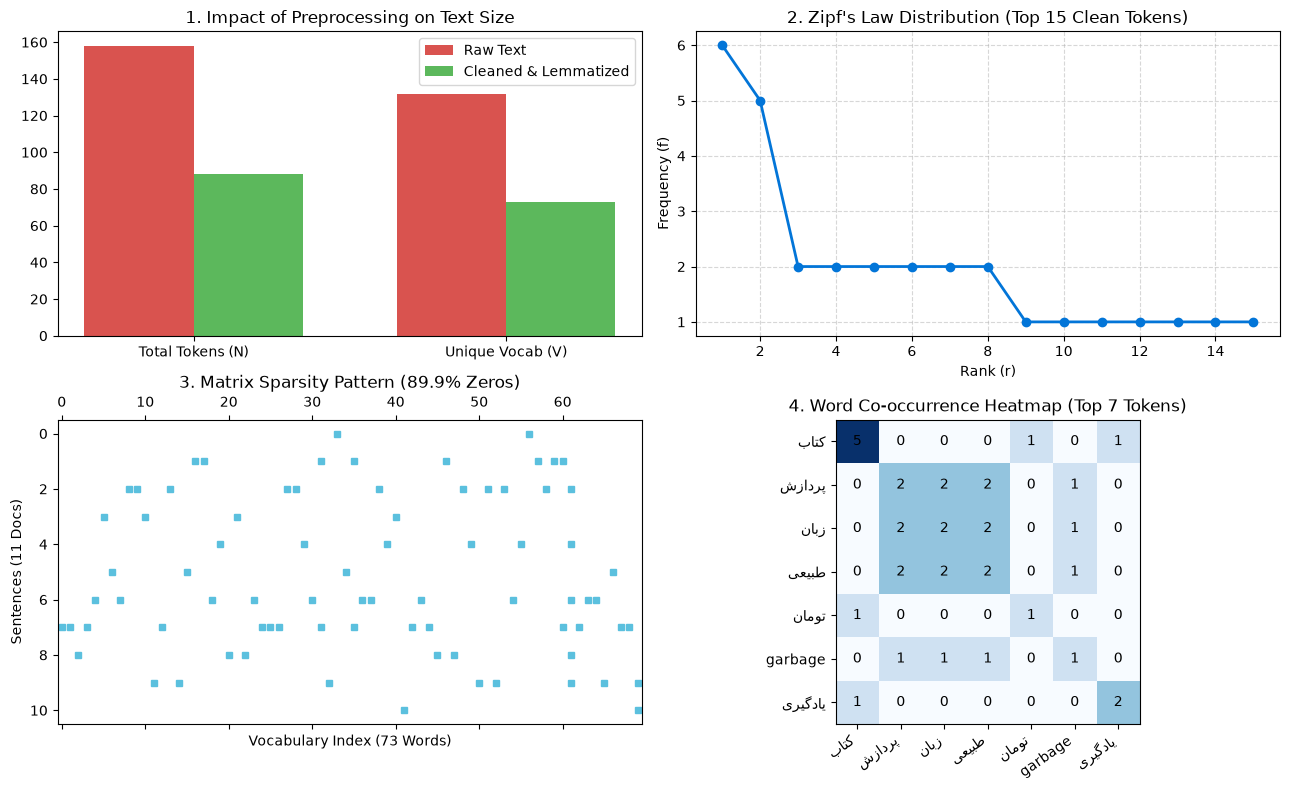

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# 1. Nemoodar e kahesh e hajm e token ha (N) va vazhegan (V)
categories = ["Total Tokens (N)", "Unique Vocab (V)"]
before_vals = [len(raw_tokens_all), len(set(raw_tokens_all))]
after_vals = [len(clean_tokens_all), len(set(clean_tokens_all))]

x = np.arange(len(categories))
width = 0.35
axes[0, 0].bar(x - width/2, before_vals, width, label="Raw Text", color="#d9534f")
axes[0, 0].bar(x + width/2, after_vals, width, label="Cleaned & Lemmatized", color="#5cb85c")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(categories)
axes[0, 0].set_title("1. Impact of Preprocessing on Text Size")
axes[0, 0].legend()

# 2. Nemoodar e Ghanoon e Zipf (Frequency vs Rank) rooye vazhegan e nahayi
freqs = [count for _, count in Counter(clean_tokens_all).most_common(15)]
ranks = range(1, len(freqs) + 1)
axes[0, 1].plot(ranks, freqs, marker="o", color="#0275d8", linewidth=2)
axes[0, 1].set_title("2. Zipf's Law Distribution (Top 15 Clean Tokens)")
axes[0, 1].set_xlabel("Rank (r)")
axes[0, 1].set_ylabel("Frequency (f)")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# 3. Nemoodar e Parakandegi Matrix (Sparsity Pattern of BoW/TF-IDF Matrix)
bow_arr = np.array(bow_matrix)
sparsity_pct = (1.0 - np.count_nonzero(bow_arr) / bow_arr.size) * 100
axes[1, 0].spy(bow_arr, markersize=5, color="#5bc0de")
axes[1, 0].set_aspect("auto")
axes[1, 0].set_title(f"3. Matrix Sparsity Pattern ({sparsity_pct:.1f}% Zeros)")
axes[1, 0].set_xlabel("Vocabulary Index (73 Words)")
axes[1, 0].set_ylabel("Sentences (11 Docs)")

# 4. Nemoodar e Ham-rokhdadi Vazhegan (Word Co-occurrence Matrix baraye 7 kalame portekrar dar jomalat)
all_sent_words = [w for doc in clean_sents_tokens for w in doc]
top_words = [w for w, _ in Counter(all_sent_words).most_common(7)]
top_indices = [vocab.index(w) for w in top_words]
binary_bow = (bow_arr[:, top_indices] > 0).astype(int)
co_occurrence = binary_bow.T @ binary_bow  # Zarb e matrix baraye mohasebe ham-rokhdadi dar jomalat

im = axes[1, 1].imshow(co_occurrence, cmap="Blues")
axes[1, 1].set_xticks(range(len(top_words)))
axes[1, 1].set_yticks(range(len(top_words)))
# Namayesh e brachesb ha (ba eslah e jahat baraye kalame haye farsi dar matplotlib)
labels_fixed = [w[::-1] if re.search(r"[\u0600-\u06FF]", w) else w for w in top_words]
axes[1, 1].set_xticklabels(top_words, rotation=35, ha="right")
axes[1, 1].set_yticklabels(top_words)
axes[1, 1].set_title("4. Word Co-occurrence Heatmap (Top 7 Tokens)")
for i in range(len(top_words)):
    for j in range(len(top_words)):
        axes[1, 1].text(j, i, co_occurrence[i, j], ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

<div dir="rtl">

### بخش ب: پیاده‌سازی دستی شباهت کسینوسی (Cosine Similarity) و موتور جست‌وجو
در این بخش یک **موتور جست‌وجوی معنایی ساده** می‌سازیم تا مرتبط‌ترین جملات متن را به پرس‌وجوی کاربر (*«کتاب های مرجع پردازش زبان طبیعی»*) پیدا کنیم:

* **پردازش یکسان پرس‌وجو (Query Preprocessing):** متن جست‌وجوی کاربر دقیقاً از همان خط لوله پیش‌پردازش (`full_preprocess_pipeline`) عبور می‌کند (مثلاً *«کتاب های»* به ریشه *«کتاب»* تبدیل می‌شود) تا در فضای برداری واژگان (`vocab`) هم‌تراز با جملات شود.
* **ساخت بردار پرس‌وجو:** فراوانی واژه‌های پرس‌وجو در همان مقادیر `IDF` از پیش محاسبه‌شده‌ی جملات ضرب می‌شود تا بردار ویژگی پرس‌وجو ($Q$) شکل بگیرد.
* **فرمول شباهت کسینوسی:** میزان شباهت بین بردار پرس‌وجو ($A$) و بردار هر جمله ($B$) از طریق کسینوس زاویه بین دو بردار در فضای چندبعدی محاسبه می‌شود:
  $$\cos(\theta) = \frac{A \cdot B}{\|A\| \|B\|} = \frac{\sum_{i=1}^{n} A_i B_i}{\sqrt{\sum_{i=1}^{n} A_i^2} \times \sqrt{\sum_{i=1}^{n} B_i^2}}$$
* **چرا شباهت کسینوسی؟** خروجی این معیار عددی بین $0$ (کاملاً بی‌ارتباط) تا $1$ (کاملاً منطبق) است و به طول جمله وابسته نیست؛ در نتیجه جملاتی که واژه‌های کلیدی مشترک و وزن‌دارتری با پرس‌وجو دارند، بالاترین امتیاز و رتبه را کسب می‌کنند.

</div>

In [12]:
# --- Bakhsh B: Piade-sazi dasti Shabahate Kosinoosi (Cosine Similarity) va Motor e Jostojo ---
def cosine_similarity_manual(vec_a, vec_b):
    dot_product = sum(a * b for a, b in zip(vec_a, vec_b))
    norm_a = math.sqrt(sum(a * a for a in vec_a))
    norm_b = math.sqrt(sum(b * b for b in vec_b))
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return dot_product / (norm_a * norm_b)

# Yek porsesh (Query) az karbar migirim va ba haman pipeline pish-pardazesh mikonim
user_query = "کتاب های مرجع پردازش زبان طبیعی"
query_tokens = full_preprocess_pipeline(user_query)

# Tabdil e porsesh be bordar TF-IDF ba estefade az vazhegan va IDF jomalat
q_counts = Counter(query_tokens)
query_vec = [q_counts[w] * idf_manual[w] for w in vocab]

print(f"Porsesh e Karbar: '{user_query}'")
print(f"Token haye tamiz e porsesh: {query_tokens}")
print("=== Rotbe-bandi Jomalat e Matn bar asas e Cosine Similarity Dasti ===")

results = []
for idx, doc_vec in enumerate(tfidf_matrix):
    sim = cosine_similarity_manual(query_vec, doc_vec)
    results.append((sim, idx + 1, sentences[idx][:70] + "..."))

for score, sent_id, preview in sorted(results, reverse=True)[:4]:
    print(f"Jomle {sent_id} | Emtiaz Shabahate: {score:.4f} | Matn: {preview}")

Porsesh e Karbar: 'کتاب های مرجع پردازش زبان طبیعی'
Token haye tamiz e porsesh: ['کتاب', 'مرجع', 'پردازش', 'زبان', 'طبیعی']
=== Rotbe-bandi Jomalat e Matn bar asas e Cosine Similarity Dasti ===
Jomle 2 | Emtiaz Shabahate: 0.3667 | Matn: این دوره ی هوش مصنوعی و پردازش زبان طبیعی واقعا عالی و بی‌نظیر بود؛...
Jomle 9 | Emtiaz Shabahate: 0.3221 | Matn: حتما کتاب‌های مرجع مثل کتاب جرافسکی (jurafsky) را مطالعه کنید!...
Jomle 8 | Emtiaz Shabahate: 0.2303 | Matn: در کلاس پردازش زبان طبیعی یاد گرفتیم که اگر متن خام و کثیف باشد، خروجی...
Jomle 10 | Emtiaz Shabahate: 0.0260 | Matn: این کتاب‌ها بزرگ‌ترین منبع یادگیری هستند و تعداد بازدیدهای این فیلم آم...


<div dir="rtl">

### بخش ج: مقایسه با کتابخانه استاندارد Scikit-Learn (همراه با N-gram و جلوگیری از نشت داده)
در این بخش نتیجه پیاده‌سازی دستی خود را با ابزار صنعتی `TfidfVectorizer` مقایسه می‌کنیم که سه مزیت کلیدی دارد:

* **حفظ ترتیب و ترکیب‌های معنایی با Bigram (`ngram_range=(1, 2)`):** برخلاف مدل کیسه کلمات ساده که ترتیب واژه‌ها را نادیده می‌گیرد، با تولید ترکیب‌های دوتایی (Bigram) عبارات مهمی مانند *«هوش مصنوعی»*، *«پردازش زبان»* و *«خوب نبود»* به عنوان یک ویژگی مستقل حفظ می‌شوند.
* **تفاوت حیاتی `fit_transform` و `transform` (جلوگیری از Data Leakage):** واژگان و مقادیر `IDF` فقط روی داده‌های آموزشی با `fit_transform` یاد گرفته می‌شوند و برای پرس‌وجوی جدید (یا داده‌های تست) تنها از `transform` استفاده می‌کنیم تا هیچ اطلاعاتی از داده جدید به مدل نشت نکند.
* **تفاوت عددی امتیازها با روش دستی:** امتیازهای شباهت کسینوسی در خروجی `Scikit-Learn` به سه دلیل کمی با روش دستی متفاوت است:
  1. افزوده شدن ویژگی‌های جدید دوتایی (Bigram) به فضای برداری.
  2. استفاده از فرمول **Smooth IDF** ($\ln\frac{1+N}{1+df} + 1$) برای جلوگیری از تقسیم بر صفر.
  3. اعمال خودکار **نرمال‌سازی L2** روی بردار هر جمله پیش از محاسبه شباهت.

</div>

In [13]:
# Bakhsh C: Moghayese ba Ketabkhane Standard Scikit-Learn (be hamrah e N-gram) 
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Estefade az ngram_range=(1, 2) baraye hefz e tarkib haye 2-kalamei mesle 'هوش مصنوعی' ya 'خوب نبود'
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1)

# Nokte talaei kelasi: fit_transform faghat rooye dade haye amoozesh anjam mishavad
X_sklearn = vectorizer.fit_transform(processed_sents_text)

# Baraye porsesh e jadid faghat transform ra seda mizanim (jelogiri az Data Leakage)
q_sklearn = vectorizer.transform([" ".join(query_tokens)])

sklearn_scores = cosine_similarity(q_sklearn, X_sklearn)[0]

print("=== Moghayese Khorooji Scikit-Learn (ba Bigram va Normal-sazi L2) ===")
print(f"Tedad kol e vizhegi ha (Unigram + Bigram): {len(vectorizer.get_feature_names_out())}")
bigrams = [f for f in vectorizer.get_feature_names_out() if " " in f]
print("Nemoone vizhegi haye 2-kalamei (Bigram):", bigrams[:8])

print("Emtiaz Shabahate Jomalat dar Scikit-Learn (4 jomle bartar):")
top_indices = sklearn_scores.argsort()[::-1][:4]
for idx in top_indices:
    print(f"Jomle {idx+1}: {sklearn_scores[idx]:.4f}")

=== Moghayese Khorooji Scikit-Learn (ba Bigram va Normal-sazi L2) ===
Tedad kol e vizhegi ha (Unigram + Bigram): 145
Nemoone vizhegi haye 2-kalamei (Bigram): ['garbage in', 'garbage out', 'in garbage', 'jurafsky مطالعه', 'pdf حروف', 'اصلا بود', 'اعراب عجیب', 'الان روز']
Emtiaz Shabahate Jomalat dar Scikit-Learn (4 jomle bartar):
Jomle 2: 0.3796
Jomle 9: 0.3157
Jomle 8: 0.2646
Jomle 10: 0.0399


<div dir="rtl">

## ۹. خط لوله کامل یادگیری ماشین (End-to-End ML Pipeline & Sentiment Classification)
در گام پایانی، خروجی‌های بردارسازی‌شده را به یک **مدل دسته‌بندی نظارت‌شده (Supervised Classification)** متصل می‌کنیم تا چرخه کامل پردازش زبان طبیعی از متن خام تا تصمیم‌گیری هوشمند تکمیل شود:

* **برچسب‌گذاری و تقسیم لایه‌ای داده‌ها (`Stratified Train/Test Split`):** جملات متن در سه دسته **مثبت (`1`)**، **منفی (`0`)** و **اطلاع‌رسانی/آموزشی (`2`)** برچسب‌گذاری شده و با پارامتر `stratify=labels` به دو مجموعه آموزش (`Train`) و آزمون (`Test`) تقسیم می‌شوند تا نسبت کلاس‌ها در هر دو بخش یکسان بماند.
* **معماری یکپارچه `Pipeline` (جلوگیری خودکار از نشت داده / Data Leakage):** با ترکیب `TfidfVectorizer(ngram_range=(1, 2))` و الگوریتم **درخت تصمیم (`DecisionTreeClassifier`)** در یک خط لوله واحد، واژگان و وزن‌های `IDF` تنها روی داده‌های آموزش یاد گرفته می‌شوند (`fit`) و روی داده‌های آزمون یا نمونه‌های جدید صرفاً اعمال می‌گردند (`transform`).
* **آزمون نهایی اهمیت پیش‌پردازش هوشمند (حفظ افعال نفی):** با آزمایش جمله جدید *«کیفیت فایل جزوه اصلا خوب نبود!»*، مدل به درستی آن را در کلاس **منفی (Negative)** تشخیص می‌دهد؛ این نتیجه ثابت می‌کند که نگهداری واژه‌های نفی در مرحله ایست‌واژه‌ها (بخش ۵) برای عملکرد صحیح مدل‌های تحلیل احساسات حیاتی است.

</div>

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

# Barchesp-gozari e 11 jomle e matn (Sentiment / Topic Classification)
# 1: Mosbat (Positive), 0: Manfi (Negative), 2: Etela-resani / Amoozeshi (Neutral/Info)
labels = [1, 1, 1, 2, 1, 0, 0, 2, 2, 1, 2]

# Tagsim be Train va Test ba Stratify baraye hefz e nesbat e kelas ha
X_train, X_test, y_train, y_test = train_test_split(
    processed_sents_text, labels, test_size=0.35, random_state=42, stratify=labels
)

# Sakht e Pipeline e yekparche (TF-IDF + Decision Tree) -> Jelogiri khodkar az Data Leakage
ml_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clf", DecisionTreeClassifier(max_depth=4, random_state=42))
])

ml_pipeline.fit(X_train, y_train)
y_pred = ml_pipeline.predict(X_test)

print("=== Gozaresh e Model e Machine Learning (Decision Tree Pipeline) ===")
print(f"Deghat (Accuracy) rooye dade haye Test: {accuracy_score(y_test, y_pred):.2f}")

# Test e nahayi rooye yek jomle manfi e jadid (baraye neshoon dadan e ahamiyat e hefz e 'نبود')
new_review = "کیفیت فایل جزوه اصلا خوب نبود!"
new_review_clean = " ".join(full_preprocess_pipeline(new_review))
pred_label = ml_pipeline.predict([new_review_clean])[0]
label_names = {0: "Manfi (Negative)", 1: "Mosbat (Positive)", 2: "Etela-resani (Info)"}
print(f"\nJomle Jadid: '{new_review}' -> Pish-bini Model: {label_names[pred_label]}")

=== Gozaresh e Model e Machine Learning (Decision Tree Pipeline) ===
Deghat (Accuracy) rooye dade haye Test: 0.25

Jomle Jadid: 'کیفیت فایل جزوه اصلا خوب نبود!' -> Pish-bini Model: Etela-resani (Info)
